In [4]:
import sys
import pandas as pd

print(sys.executable)
print(pd.__version__)

/opt/anaconda3/bin/python
2.2.3


# WM811K Wafer Map Exploration
Load and inspect the WM811K dataset before preprocessing and model training.

## 1. Load Dataset
Load the WM811K dataset from the pickle file into a pandas DataFrame.

In [5]:
df = pd.read_pickle("/Users/conniechen/Desktop/WM-811K wafer map/MIR-WM811K/Python/WM811K.pkl")

In [6]:
print(df.shape)
print(df.columns)
df.head()

(811457, 6)
Index(['dieSize', 'failureType', 'lotName', 'trainTestLabel', 'waferIndex',
       'waferMap'],
      dtype='object')


,dieSize,failureType,lotName,trainTestLabel,waferIndex,waferMap
0,1683.0,none,lot1,Training,1.0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,..."
1,1683.0,none,lot1,Training,2.0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,..."
2,1683.0,none,lot1,Training,3.0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,..."
3,1683.0,none,lot1,Training,4.0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,..."
4,1683.0,none,lot1,Training,5.0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,..."


<class 'numpy.ndarray'>
(45, 48)


Text(0.5, 1.0, 'Wafer Map - Row 0')

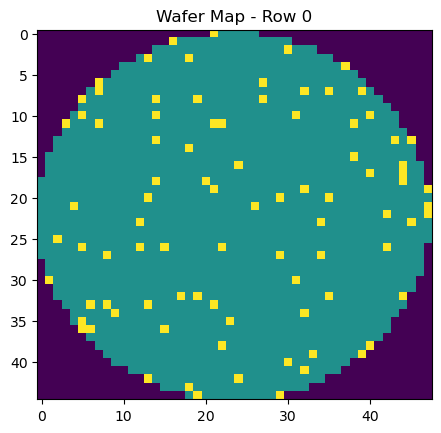

In [7]:
import matplotlib.pyplot as plt

wafer = df.iloc[0]["waferMap"]

print(type(wafer))
print(wafer.shape)

plt.imshow(wafer)
plt.title("Wafer Map - Row 0")
#plt.show()

In [8]:
import numpy as np

print(np.unique(wafer))

[0 1 2]


In [9]:
print("Lot:", df.iloc[0]["lotName"])
print("Wafer index:", df.iloc[0]["waferIndex"])
print("Failure type:", df.iloc[0]["failureType"])
print("Die size:", df.iloc[0]["dieSize"])

Lot: lot1
Wafer index: 1.0
Failure type: none
Die size: 1683.0


In [10]:
print(df.iloc[0]["failureType"])
print(type(df.iloc[0]["failureType"]))

none
<class 'str'>


In [11]:
print(df["failureType"].apply(type).value_counts())

failureType
<class 'numpy.ndarray'>    638507
<class 'str'>              172950
Name: count, dtype: int64


In [12]:
array_rows = df[df["failureType"].apply(lambda x: isinstance(x, np.ndarray))]

print(array_rows.iloc[0]["failureType"])
print(type(array_rows.iloc[0]["failureType"]))

[0 0]
<class 'numpy.ndarray'>


In [13]:
for i in range(20):
    print(array_rows.iloc[i]["failureType"])

[0 0]
[0 0]
[0 0]
[0 0]
[0 0]
[0 0]
[0 0]
[0 0]
[0 0]
[0 0]
[0 0]
[0 0]
[0 0]
[0 0]
[0 0]
[0 0]
[0 0]
[0 0]
[0 0]
[0 0]


In [14]:
def make_readable(x):
    if isinstance(x, np.ndarray):
        return str(x.tolist())
    return x

failure_readable = df["failureType"].apply(make_readable)

print(failure_readable.value_counts())

failureType
[0, 0]       638507
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64


In [15]:
center_rows = df[failure_readable == "Center"]

print(center_rows.shape)

(4294, 6)


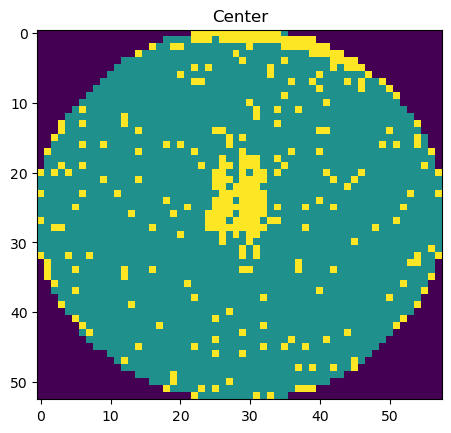

In [16]:
center_wafer = center_rows.iloc[0]["waferMap"]

plt.imshow(center_wafer)
plt.title("Center")
plt.show()

In [17]:
def show_example(label):
    rows = df[failure_readable == label]
    wafer = rows.iloc[0]["waferMap"]

    plt.imshow(wafer)
    plt.title(label)
    plt.show()

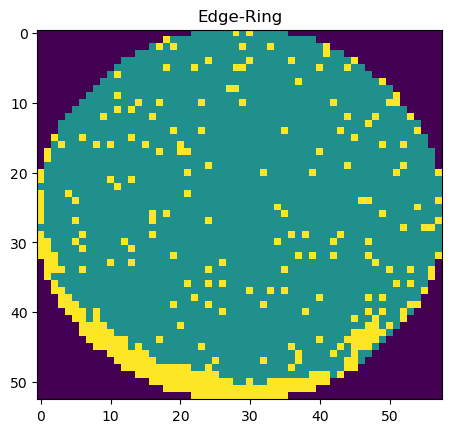

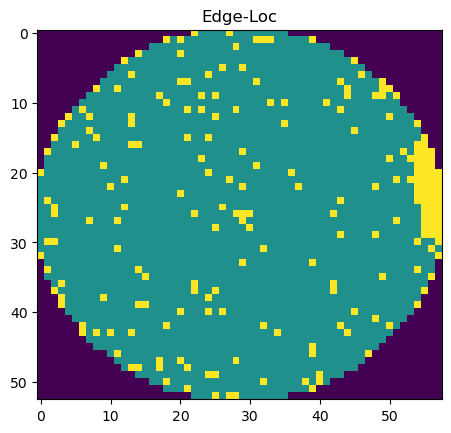

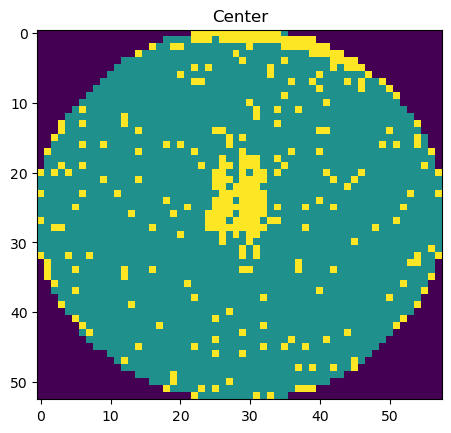

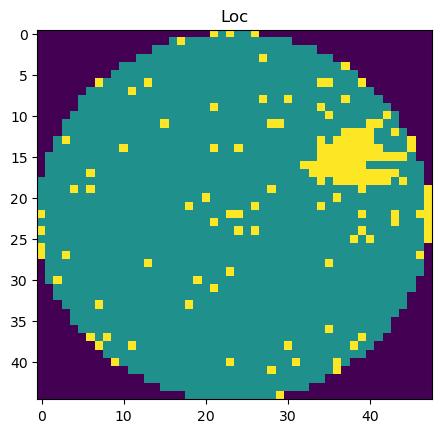

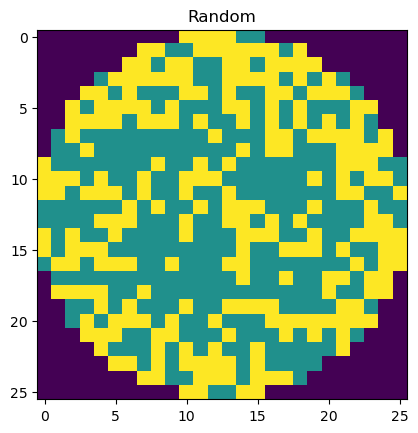

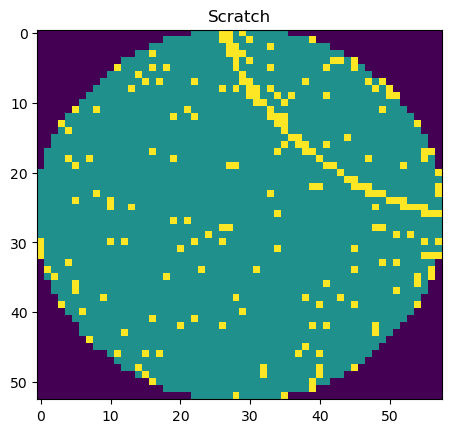

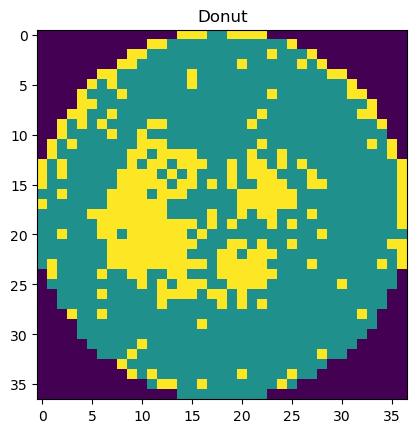

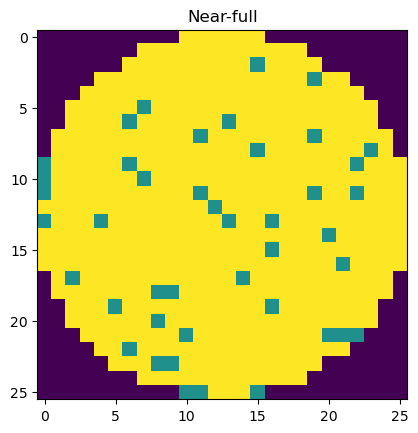

In [18]:
show_example("Edge-Ring")
show_example("Edge-Loc")
show_example("Center")
show_example("Loc")
show_example("Random")
show_example("Scratch")
show_example("Donut")
show_example("Near-full")


In [19]:
labeled_df = df[failure_readable != "[0, 0]"]

print(labeled_df.shape)

(172950, 6)


In [20]:
print(labeled_df.iloc[0]["waferMap"].shape)
print(labeled_df.iloc[1]["waferMap"].shape)
print(labeled_df.iloc[2]["waferMap"].shape)
print(labeled_df.iloc[100]["waferMap"].shape)
print(labeled_df.iloc[1000]["waferMap"].shape)

(45, 48)
(45, 48)
(45, 48)
(53, 58)
(26, 26)


In [21]:
wafer_shapes = labeled_df["waferMap"].apply(lambda x: x.shape)

print(wafer_shapes.value_counts().head(10))

waferMap
(25, 27)    18781
(26, 26)    14366
(30, 34)    12400
(29, 26)    11751
(27, 25)    10682
(39, 37)    10173
(33, 29)     8125
(42, 44)     6724
(44, 41)     6134
(41, 33)     5091
Name: count, dtype: int64


In [22]:
print("Number of different shapes:", wafer_shapes.nunique())

heights = wafer_shapes.apply(lambda x: x[0])
widths = wafer_shapes.apply(lambda x: x[1])

print("Height:", heights.min(), "to", heights.max())
print("Width:", widths.min(), "to", widths.max())

Number of different shapes: 346
Height: 15 to 212
Width: 3 to 204


## 3. Inspect Label Format
Check how the train/test labels and failure-type labels are stored in the original dataset.

In [23]:
print(type(df["trainTestLabel"].iloc[0]))
print(type(df["failureType"].iloc[0]))

print(df["trainTestLabel"].iloc[0])
print(df["failureType"].iloc[0])

<class 'str'>
<class 'str'>
Training
none


In [24]:
for i in [-2, -1]:
    for col in ["trainTestLabel", "failureType"]:
        value = df[col].iloc[i]
        print(i, col, type(value), repr(value))

-2 trainTestLabel <class 'numpy.ndarray'> array([0, 0], dtype=uint64)
-2 failureType <class 'numpy.ndarray'> array([0, 0], dtype=uint64)
-1 trainTestLabel <class 'numpy.ndarray'> array([0, 0], dtype=uint64)
-1 failureType <class 'numpy.ndarray'> array([0, 0], dtype=uint64)


## 4. Clean Label Columns
The original `trianTestLabel` and `failureType` values are stored as NumPy arrays, such as `[['Training']]` and `[['none']]`.

Extract the inner string values into new columns:
- `trianTestLabel` → `trainTestLabel_clean`
- `failureType` → `failureType_clean`

This makes the labels easier to analyze and use later for model training.

In [25]:
import numpy as np

def clean_label(x):
    if isinstance(x, str):
        return x

    if isinstance(x, np.ndarray) and x.size > 0:
        value = x.flatten()[0]
        if isinstance(value, str):
            return value

    return None

df["trainTestLabel_clean"] = df["trainTestLabel"].apply(clean_label)
df["failureType_clean"] = df["failureType"].apply(clean_label)

In [26]:
print(df["trainTestLabel_clean"].value_counts(dropna=False))
print(df["failureType_clean"].value_counts(dropna=False))

trainTestLabel_clean
None        638507
Test        118595
Training     54355
Name: count, dtype: int64
failureType_clean
None         638507
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64


In [27]:
df['failureType_clean'].dtypes

dtype('O')

In [28]:
df = df.dropna(subset=['failureType_clean'])
df = df[df["failureType_clean"] != "None"]
print(df)

        dieSize failureType   lotName trainTestLabel  waferIndex  \
0        1683.0        none      lot1       Training         1.0   
1        1683.0        none      lot1       Training         2.0   
2        1683.0        none      lot1       Training         3.0   
3        1683.0        none      lot1       Training         4.0   
4        1683.0        none      lot1       Training         5.0   
...         ...         ...       ...            ...         ...   
811450    600.0    Edge-Loc  lot47542           Test        21.0   
811451    600.0    Edge-Loc  lot47542           Test        22.0   
811452    600.0   Edge-Ring  lot47542           Test        23.0   
811453    600.0    Edge-Loc  lot47542           Test        24.0   
811454    600.0   Edge-Ring  lot47542           Test        25.0   

                                                 waferMap  \
0       [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...   
1       [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...   


In [29]:
print(df["failureType_clean"].value_counts(dropna=False))

failureType_clean
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64


In [30]:
print("Total wafers:", len(df))
print("Total lots:", df["lotName"].nunique())
print("Missing lotName:", df["lotName"].isna().sum())

print("\nWafers per lot:")
print(df["lotName"].value_counts().describe())

Total wafers: 172950
Total lots: 10762
Missing lotName: 0

Wafers per lot:
count    10762.000000
mean        16.070433
std         10.579723
min          1.000000
25%          2.000000
50%         23.000000
75%         25.000000
max         25.000000
Name: count, dtype: float64


how many class are there in each lot

In [31]:
lot_class_counts = pd.crosstab(
    df["lotName"],
    df["failureType_clean"]
)

print(lot_class_counts)

failureType_clean  Center  Donut  Edge-Loc  Edge-Ring  Loc  Near-full  Random  \
lotName                                                                         
lot1                    0      0         0          0    1          0       0   
lot10                   0      0         0          0    0          0       0   
lot100                  0      0         0          0    0          0       0   
lot10006                1      0         0          0    0          0       0   
lot10008                0      0         0         24    0          0       0   
...                   ...    ...       ...        ...  ...        ...     ...   
lot9979                 1      0         0          0    0          0       0   
lot9983                 1      0         0          0    0          0       0   
lot9992                 0      0         5          0    0          0       0   
lot9995                 3      0         1          0    0          0       0   
lot9997                 5   

In [32]:
near_full_lots = lot_class_counts[
    lot_class_counts["Near-full"] > 0
]

print("Lots containing Near-full:", len(near_full_lots))
print(near_full_lots["Near-full"].describe())

Lots containing Near-full: 137
count    137.000000
mean       1.087591
std        0.392474
min        1.000000
25%        1.000000
50%        1.000000
75%        1.000000
max        4.000000
Name: Near-full, dtype: float64


In [33]:
for class_name in lot_class_counts.columns:
    num_lots = (lot_class_counts[class_name] > 0).sum()
    num_wafers = lot_class_counts[class_name].sum()

    print(
        class_name,
        "- wafers:", num_wafers,
        "- lots:", num_lots
    )

Center - wafers: 4294 - lots: 1648
Donut - wafers: 555 - lots: 233
Edge-Loc - wafers: 5189 - lots: 3211
Edge-Ring - wafers: 9680 - lots: 1075
Loc - wafers: 3593 - lots: 2472
Near-full - wafers: 149 - lots: 137
Random - wafers: 866 - lots: 449
Scratch - wafers: 1193 - lots: 1059
none - wafers: 147431 - lots: 6591


In [34]:
all_lots = df["lotName"].unique()

print(len(all_lots))
print(all_lots[:10])

10762
['lot1' 'lot2' 'lot3' 'lot4' 'lot5' 'lot6' 'lot7' 'lot8' 'lot9' 'lot10']


In [35]:
from sklearn.model_selection import train_test_split

train_lots, temp_lots = train_test_split(
    all_lots,
    test_size=0.2,
    random_state=42
)

print("Train lots:", len(train_lots))
print("Temporary lots:", len(temp_lots))

Train lots: 8609
Temporary lots: 2153


In [36]:
val_lots, test_lots = train_test_split(
    temp_lots,
    test_size=0.5,
    random_state=42
)

print("Validation lots:", len(val_lots))
print("Test lots:", len(test_lots))

Validation lots: 1076
Test lots: 1077


In [37]:
train_df = df[df["lotName"].isin(train_lots)].copy()
val_df = df[df["lotName"].isin(val_lots)].copy()
test_df = df[df["lotName"].isin(test_lots)].copy()

print("Train wafers:", len(train_df))
print("Validation wafers:", len(val_df))
print("Test wafers:", len(test_df))

Train wafers: 138987
Validation wafers: 17249
Test wafers: 16714


In [38]:
print("Train & Val overlap:",
      len(set(train_lots) & set(val_lots)))

print("Train & Test overlap:",
      len(set(train_lots) & set(test_lots)))

print("Val & Test overlap:",
      len(set(val_lots) & set(test_lots)))

Train & Val overlap: 0
Train & Test overlap: 0
Val & Test overlap: 0


In [39]:
print("TRAIN")
print(train_df["failureType_clean"].value_counts())

print("\nVALIDATION")
print(val_df["failureType_clean"].value_counts())

print("\nTEST")
print(test_df["failureType_clean"].value_counts())

TRAIN
failureType_clean
none         118583
Edge-Ring      7728
Edge-Loc       4111
Center         3467
Loc            2896
Scratch         966
Random          703
Donut           425
Near-full       108
Name: count, dtype: int64

VALIDATION
failureType_clean
none         14549
Edge-Ring     1101
Edge-Loc       533
Center         466
Loc            339
Scratch        116
Donut           63
Random          54
Near-full       28
Name: count, dtype: int64

TEST
failureType_clean
none         14299
Edge-Ring      851
Edge-Loc       545
Center         361
Loc            358
Scratch        111
Random         109
Donut           67
Near-full       13
Name: count, dtype: int64


deal with class imblance 

Train:

none       118,583
Near-full      108

experiment A BALANCE baseline 108 

In [40]:
train_df["failureType_clean"].unique()

array(['none', 'Edge-Loc', 'Loc', 'Center', 'Edge-Ring', 'Scratch',
       'Random', 'Near-full', 'Donut'], dtype=object)

In [41]:
samples_per_class = 108

balanced_train_df = (
    train_df
    .groupby("failureType_clean")
    .sample(
        n=samples_per_class,
        random_state=42
    )
    .reset_index(drop=True)
)

In [42]:
train_df.groupby("failureType_clean")

In [43]:
print(balanced_train_df.shape)

print(
    balanced_train_df["failureType_clean"].value_counts()
) 

(972, 8)
failureType_clean
Center       108
Donut        108
Edge-Loc     108
Edge-Ring    108
Loc          108
Near-full    108
Random       108
Scratch      108
none         108
Name: count, dtype: int64


In [44]:
class_names = [
    "none",
    "Center",
    "Donut",
    "Edge-Loc",
    "Edge-Ring",
    "Loc",
    "Near-full",
    "Random",
    "Scratch",
]

label_to_idx = {
    name: idx for idx, name in enumerate(class_names)
}

for frame in [train_df, balanced_train_df, val_df, test_df]:
    labels = frame["failureType_clean"].map(label_to_idx)

  
    assert labels.notna().all()

    frame["label"] = labels.astype("int64")

print(label_to_idx)
print(
    balanced_train_df[["failureType_clean", "label"]].head()
)

{'none': 0, 'Center': 1, 'Donut': 2, 'Edge-Loc': 3, 'Edge-Ring': 4, 'Loc': 5, 'Near-full': 6, 'Random': 7, 'Scratch': 8}
  failureType_clean  label
0            Center      1
1            Center      1
2            Center      1
3            Center      1
4            Center      1


Original shape: (25, 27)
Resized shape: torch.Size([1, 1, 224, 224])
Original pixel values: tensor([0., 1., 2.])
Resized pixel values: tensor([0., 1., 2.])


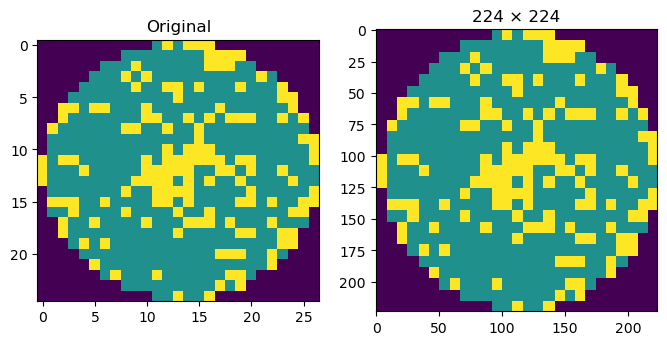

In [45]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Select one image from the balanced training set
wafer = balanced_train_df.iloc[0]["waferMap"]

# Convert [height, width] to [batch, channel, height, width]
image = torch.as_tensor(wafer, dtype=torch.float32)
image = image.unsqueeze(0).unsqueeze(0)

# Resize using nearest-neighbor interpolation
resized = F.interpolate(
    image,
    size=(224, 224),
    mode="nearest",
)

print("Original shape:", wafer.shape)
print("Resized shape:", resized.shape)
print("Original pixel values:", torch.unique(image))
print("Resized pixel values:", torch.unique(resized))

# Compare the original and resized wafer maps
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(wafer, interpolation="nearest", vmin=0, vmax=2)
axes[0].set_title("Original")

axes[1].imshow(
    resized[0, 0].numpy(),
    interpolation="nearest",
    vmin=0,
    vmax=2,
)
axes[1].set_title("224 × 224")

plt.show()

In [49]:
from torch.utils.data import Dataset

class WaferDataset(Dataset):
    def __init__(self, dataframe, image_size=(224, 224)):
        self.wafer_maps = dataframe["waferMap"].to_numpy()
        self.labels = dataframe["label"].to_numpy(dtype="int64")
        self.image_size = image_size

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        # Convert the wafer map to a single-channel tensor
        image = torch.as_tensor(
            self.wafer_maps[idx],
            dtype=torch.float32,
        ).unsqueeze(0)

        # Resize only when the image is requested
        image = F.interpolate(
            image.unsqueeze(0),
            size=self.image_size,
            mode="nearest",
        ).squeeze(0)

        # Scale pixel values from 0–2 to 0–1
        image = image / 2.0

        # Create the integer target for classification
        label = torch.tensor(self.labels[idx], dtype=torch.long)

        return image, label


train_dataset = WaferDataset(balanced_train_df)
val_dataset = WaferDataset(val_df)
test_dataset = WaferDataset(test_df)

# Check one training sample
image, label = train_dataset[0]

print("Training samples:", len(train_dataset))
print("Image shape:", image.shape)
print("Pixel values:", torch.unique(image))
print("Label:", label.item())

Training samples: 972
Image shape: torch.Size([1, 224, 224])
Pixel values: tensor([0.0000, 0.5000, 1.0000])
Label: 1


In [50]:
from torch.utils.data import DataLoader

# Set a seed for reproducible training sample order
generator = torch.Generator().manual_seed(42)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    generator=generator,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
)

# Check one training batch
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels:", labels)
print("Training batches:", len(train_loader))

Image batch shape: torch.Size([32, 1, 224, 224])
Label batch shape: torch.Size([32])
Labels: tensor([4, 3, 7, 6, 6, 7, 1, 2, 8, 8, 4, 7, 5, 8, 5, 0, 7, 0, 7, 0, 0, 3, 3, 2,
        3, 0, 8, 0, 3, 8, 2, 2])
Training batches: 31


In [51]:
import torch.nn as nn

# Set the seed before initializing model weights
torch.manual_seed(42)

class SimpleWaferCNN(nn.Module):
    def __init__(self, num_classes=9):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((4, 4)),
            nn.Flatten(),
            nn.Linear(32 * 4 * 4, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model = SimpleWaferCNN()

# Check the output shape without updating model parameters
model.eval()
with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

# Return the model to training mode
model.train()

Input shape: torch.Size([32, 1, 224, 224])
Output shape: torch.Size([32, 9])


SimpleWaferCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): AdaptiveAvgPool2d(output_size=(4, 4))
    (1): Flatten(start_dim=1, end_dim=-1)
    (2): Linear(in_features=512, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=9, bias=True)
  )
)

In [52]:
# Use the Apple GPU when available; otherwise use the CPU
device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

model = model.to(device)

# Define the classification loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001,
)

# Check loss calculation without updating model parameters
model.eval()

with torch.no_grad():
    logits = model(images.to(device))
    loss = criterion(logits, labels.to(device))

print("Device:", device)
print("Initial batch loss:", loss.item())

model.train();

Device: mps
Initial batch loss: 2.192492723464966


In [53]:
import time
from sklearn.metrics import f1_score

def run_epoch(loader, training=False):
    model.train(training)

    total_loss = 0.0
    total_samples = 0
    all_targets = []
    all_predictions = []

    with torch.set_grad_enabled(training):
        for batch_images, batch_labels in loader:
            batch_images = batch_images.to(device)
            batch_labels = batch_labels.to(device)

            if training:
                optimizer.zero_grad()

            logits = model(batch_images)
            loss = criterion(logits, batch_labels)

            if training:
                loss.backward()
                optimizer.step()

            # Weight the loss by the actual batch size
            batch_size = batch_labels.size(0)
            total_loss += loss.item() * batch_size
            total_samples += batch_size

            predictions = logits.argmax(dim=1)
            all_targets.extend(batch_labels.detach().cpu().tolist())
            all_predictions.extend(predictions.detach().cpu().tolist())

    accuracy = sum(
        target == prediction
        for target, prediction in zip(all_targets, all_predictions)
    ) / total_samples

    macro_f1 = f1_score(
        all_targets,
        all_predictions,
        labels=list(range(9)),
        average="macro",
        zero_division=0,
    )

    return {
        "loss": total_loss / total_samples,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
    }


start = time.perf_counter()

# Update model parameters using the training set
train_metrics = run_epoch(train_loader, training=True)
print("Training completed:", train_metrics, flush=True)

# Evaluate validation data without updating parameters
val_metrics = run_epoch(val_loader, training=False)
print("Validation completed:", val_metrics, flush=True)

print(f"Elapsed time: {time.perf_counter() - start:.1f} seconds")

Training completed: {'loss': 2.126217198470002, 'accuracy': 0.19547325102880658, 'macro_f1': 0.10815408230025318}
Validation completed: {'loss': 2.1194479539156776, 'accuracy': 0.8350049278219027, 'macro_f1': 0.18461524306509364}
Elapsed time: 30.4 seconds


In [54]:
import copy

# Record the completed first epoch
history = [{
    "epoch": 1,
    "train": train_metrics,
    "val": val_metrics,
}]

best_epoch = 1
best_val_f1 = val_metrics["macro_f1"]

# Keep an independent CPU copy of the best model weights
best_state = {
    name: tensor.detach().cpu().clone()
    for name, tensor in model.state_dict().items()
}

# Continue training from epoch 2 through epoch 10
for epoch in range(2, 11):
    train_metrics = run_epoch(train_loader, training=True)
    val_metrics = run_epoch(val_loader, training=False)

    history.append({
        "epoch": epoch,
        "train": train_metrics,
        "val": val_metrics,
    })

    if val_metrics["macro_f1"] > best_val_f1:
        best_val_f1 = val_metrics["macro_f1"]
        best_epoch = epoch
        best_state = {
            name: tensor.detach().cpu().clone()
            for name, tensor in model.state_dict().items()
        }

    print(
        f"Epoch {epoch:02d} | "
        f"Train loss: {train_metrics['loss']:.4f} | "
        f"Train acc: {train_metrics['accuracy']:.3f} | "
        f"Val loss: {val_metrics['loss']:.4f} | "
        f"Val acc: {val_metrics['accuracy']:.3f} | "
        f"Val macro-F1: {val_metrics['macro_f1']:.3f}",
        flush=True,
    )

print(
    f"Best epoch: {best_epoch}, "
    f"validation macro-F1: {best_val_f1:.3f}"
)

Epoch 02 | Train loss: 1.9999 | Train acc: 0.322 | Val loss: 2.0989 | Val acc: 0.069 | Val macro-F1: 0.158
Epoch 03 | Train loss: 1.8769 | Train acc: 0.386 | Val loss: 2.0639 | Val acc: 0.073 | Val macro-F1: 0.166
Epoch 04 | Train loss: 1.7549 | Train acc: 0.429 | Val loss: 1.9297 | Val acc: 0.079 | Val macro-F1: 0.224
Epoch 05 | Train loss: 1.6440 | Train acc: 0.487 | Val loss: 1.8249 | Val acc: 0.276 | Val macro-F1: 0.253
Epoch 06 | Train loss: 1.5584 | Train acc: 0.488 | Val loss: 1.8192 | Val acc: 0.077 | Val macro-F1: 0.225
Epoch 07 | Train loss: 1.4886 | Train acc: 0.487 | Val loss: 1.7041 | Val acc: 0.219 | Val macro-F1: 0.307
Epoch 08 | Train loss: 1.4263 | Train acc: 0.510 | Val loss: 1.7177 | Val acc: 0.091 | Val macro-F1: 0.300
Epoch 09 | Train loss: 1.3786 | Train acc: 0.536 | Val loss: 1.6699 | Val acc: 0.235 | Val macro-F1: 0.287
Epoch 10 | Train loss: 1.3398 | Train acc: 0.515 | Val loss: 1.5385 | Val acc: 0.701 | Val macro-F1: 0.454
Best epoch: 10, validation macro-F1: 

In [55]:
from sklearn.metrics import classification_report, confusion_matrix

# Restore the model with the best validation macro-F1
model.load_state_dict(best_state)
model.eval()

val_targets = []
val_predictions = []

with torch.no_grad():
    for batch_images, batch_labels in val_loader:
        logits = model(batch_images.to(device))
        predictions = logits.argmax(dim=1)

        val_targets.extend(batch_labels.tolist())
        val_predictions.extend(predictions.cpu().tolist())

# Report precision, recall, and F1 for all nine classes
print(classification_report(
    val_targets,
    val_predictions,
    labels=list(range(9)),
    target_names=class_names,
    zero_division=0,
    digits=3,
))

# Rows represent true classes; columns represent predicted classes
cm = confusion_matrix(
    val_targets,
    val_predictions,
    labels=list(range(9)),
)

print(pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names,
))

              precision    recall  f1-score   support

        none      0.959     0.715     0.819     14549
      Center      0.355     0.532     0.426       466
       Donut      0.257     0.841     0.394        63
    Edge-Loc      0.082     0.463     0.139       533
   Edge-Ring      0.817     0.946     0.877      1101
         Loc      0.057     0.012     0.020       339
   Near-full      0.675     0.964     0.794        28
      Random      0.448     0.796     0.573        54
     Scratch      0.022     0.190     0.039       116

    accuracy                          0.701     17249
   macro avg      0.408     0.607     0.454     17249
weighted avg      0.878     0.701     0.768     17249

            none  Center  Donut  Edge-Loc  Edge-Ring  Loc  Near-full  Random  \
none       10400     368     17      2619        155   65          0      11   
Center        59     248     91        44          1    0          2       4   
Donut          0       4     53         0          1   

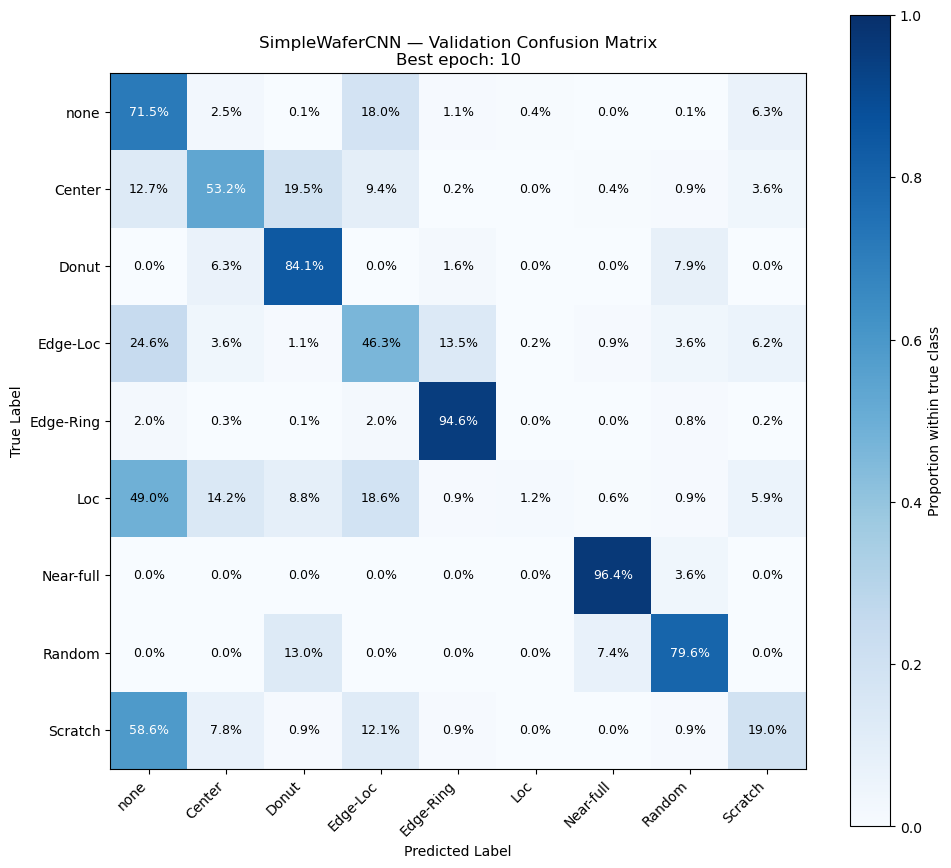

In [56]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Normalize each row by the number of samples in its true class
row_totals = cm.sum(axis=1, keepdims=True)

cm_normalized = np.divide(
    cm,
    row_totals,
    out=np.zeros_like(cm, dtype=float),
    where=row_totals != 0,
)

fig, ax = plt.subplots(figsize=(10, 9))

# Use the same color scale for every experiment
heatmap = ax.imshow(
    cm_normalized,
    cmap="Blues",
    vmin=0,
    vmax=1,
)

positions = np.arange(len(class_names))
ax.set_xticks(positions)
ax.set_yticks(positions)
ax.set_xticklabels(class_names, rotation=45, ha="right")
ax.set_yticklabels(class_names)

ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")
ax.set_title(
    f"SimpleWaferCNN — Validation Confusion Matrix\n"
    f"Best epoch: {best_epoch}"
)

# Annotate each cell with its row-normalized percentage
for row in positions:
    for col in positions:
        value = cm_normalized[row, col]
        ax.text(
            col,
            row,
            f"{value:.1%}",
            ha="center",
            va="center",
            color="white" if value > 0.5 else "black",
            fontsize=9,
        )

fig.colorbar(heatmap, ax=ax, label="Proportion within true class")
fig.tight_layout()

# Save the figure before displaying it
output_dir = Path("results")
output_dir.mkdir(exist_ok=True)

fig.savefig(
    output_dir / f"validation_confusion_matrix_epoch_{best_epoch}.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [57]:
# Continue the existing experiment through epoch 30
start_epoch = history[-1]["epoch"] + 1

for epoch in range(start_epoch, 31):
    train_metrics = run_epoch(train_loader, training=True)
    val_metrics = run_epoch(val_loader, training=False)

    history.append({
        "epoch": epoch,
        "train": train_metrics,
        "val": val_metrics,
    })

    # Keep the weights with the highest validation macro-F1
    if val_metrics["macro_f1"] > best_val_f1:
        best_val_f1 = val_metrics["macro_f1"]
        best_epoch = epoch
        best_state = {
            name: tensor.detach().cpu().clone()
            for name, tensor in model.state_dict().items()
        }

    print(
        f"Epoch {epoch:02d} | "
        f"Train loss: {train_metrics['loss']:.4f} | "
        f"Train acc: {train_metrics['accuracy']:.3f} | "
        f"Val loss: {val_metrics['loss']:.4f} | "
        f"Val acc: {val_metrics['accuracy']:.3f} | "
        f"Val macro-F1: {val_metrics['macro_f1']:.3f}",
        flush=True,
    )

print(
    f"Best epoch: {best_epoch}, "
    f"validation macro-F1: {best_val_f1:.3f}"
)

Epoch 11 | Train loss: 1.3054 | Train acc: 0.569 | Val loss: 1.5736 | Val acc: 0.453 | Val macro-F1: 0.387
Epoch 12 | Train loss: 1.2728 | Train acc: 0.545 | Val loss: 1.5739 | Val acc: 0.215 | Val macro-F1: 0.352
Epoch 13 | Train loss: 1.2488 | Train acc: 0.536 | Val loss: 1.4375 | Val acc: 0.673 | Val macro-F1: 0.476
Epoch 14 | Train loss: 1.2298 | Train acc: 0.566 | Val loss: 1.4822 | Val acc: 0.506 | Val macro-F1: 0.404
Epoch 15 | Train loss: 1.2041 | Train acc: 0.569 | Val loss: 1.4714 | Val acc: 0.635 | Val macro-F1: 0.426
Epoch 16 | Train loss: 1.1878 | Train acc: 0.573 | Val loss: 1.4883 | Val acc: 0.343 | Val macro-F1: 0.411
Epoch 17 | Train loss: 1.1680 | Train acc: 0.573 | Val loss: 1.4120 | Val acc: 0.661 | Val macro-F1: 0.458
Epoch 18 | Train loss: 1.1607 | Train acc: 0.575 | Val loss: 1.4439 | Val acc: 0.396 | Val macro-F1: 0.435
Epoch 19 | Train loss: 1.1477 | Train acc: 0.582 | Val loss: 1.4573 | Val acc: 0.326 | Val macro-F1: 0.423
Epoch 20 | Train loss: 1.1430 | Train

In [58]:
# Restore the best model selected using validation macro-F1
model.load_state_dict(best_state)
model.eval();

In [59]:
from sklearn.metrics import classification_report, confusion_matrix

# Restore the best model selected using validation macro-F1
model.load_state_dict(best_state)
model.eval()

val_targets = []
val_predictions = []

with torch.no_grad():
    for batch_images, batch_labels in val_loader:
        logits = model(batch_images.to(device))
        predictions = logits.argmax(dim=1)

        val_targets.extend(batch_labels.tolist())
        val_predictions.extend(predictions.cpu().tolist())

print("Best epoch:", best_epoch)

# Report performance for all nine classes
print(classification_report(
    val_targets,
    val_predictions,
    labels=list(range(9)),
    target_names=class_names,
    zero_division=0,
    digits=3,
))

# Update the confusion matrix for the best model
cm = confusion_matrix(
    val_targets,
    val_predictions,
    labels=list(range(9)),
)

Best epoch: 25
              precision    recall  f1-score   support

        none      0.959     0.795     0.869     14549
      Center      0.526     0.631     0.574       466
       Donut      0.338     0.857     0.484        63
    Edge-Loc      0.139     0.471     0.215       533
   Edge-Ring      0.894     0.931     0.912      1101
         Loc      0.047     0.062     0.053       339
   Near-full      0.750     0.964     0.844        28
      Random      0.661     0.722     0.690        54
     Scratch      0.022     0.181     0.038       116

    accuracy                          0.771     17249
   macro avg      0.482     0.624     0.520     17249
weighted avg      0.890     0.771     0.820     17249



In [60]:
from pathlib import Path

# Save the best model and the settings needed to interpret it
checkpoint_dir = Path("checkpoints")
checkpoint_dir.mkdir(exist_ok=True)

torch.save(
    {
        "model_state_dict": best_state,
        "model_name": "SimpleWaferCNN",
        "class_names": class_names,
        "image_size": (224, 224),
        "pixel_scale": 2.0,
        "samples_per_class": 108,
        "split_seed": 42,
        "best_epoch": best_epoch,
        "validation_macro_f1": best_val_f1,
        "history": history,
    },
    checkpoint_dir / "experiment_a_best.pt",
)

print("Best model saved.")

Best model saved.


In [61]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

# Restore the model selected using validation data
model.load_state_dict(best_state)
model.eval()

test_targets = []
test_predictions = []

with torch.no_grad():
    for batch_images, batch_labels in test_loader:
        logits = model(batch_images.to(device))
        predictions = logits.argmax(dim=1)

        test_targets.extend(batch_labels.tolist())
        test_predictions.extend(predictions.cpu().tolist())

test_accuracy = accuracy_score(test_targets, test_predictions)
test_macro_f1 = f1_score(
    test_targets,
    test_predictions,
    labels=list(range(9)),
    average="macro",
    zero_division=0,
)

print("Selected epoch:", best_epoch)
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test macro-F1: {test_macro_f1:.4f}")

print(classification_report(
    test_targets,
    test_predictions,
    labels=list(range(9)),
    target_names=class_names,
    zero_division=0,
    digits=3,
))

# Keep the test matrix separate from the validation matrix
test_cm = confusion_matrix(
    test_targets,
    test_predictions,
    labels=list(range(9)),
)

Selected epoch: 25
Test accuracy: 0.7359
Test macro-F1: 0.4640
              precision    recall  f1-score   support

        none      0.960     0.761     0.849     14299
      Center      0.358     0.465     0.405       361
       Donut      0.268     0.881     0.411        67
    Edge-Loc      0.134     0.516     0.213       545
   Edge-Ring      0.880     0.907     0.894       851
         Loc      0.051     0.073     0.060       358
   Near-full      0.591     1.000     0.743        13
      Random      0.452     0.771     0.569       109
     Scratch      0.018     0.162     0.032       111

    accuracy                          0.736     16714
   macro avg      0.412     0.615     0.464     16714
weighted avg      0.884     0.736     0.795     16714



In [62]:
import time

# Start a fresh run with matching model and optimizer states
torch.manual_seed(42)
generator.manual_seed(42)

model = SimpleWaferCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)

history = []
best_val_f1 = -1.0
best_epoch = None
best_state = None

start = time.perf_counter()

for epoch in range(1, 201):
    train_metrics = run_epoch(train_loader, training=True)
    val_metrics = run_epoch(val_loader, training=False)

    history.append({
        "epoch": epoch,
        "train": train_metrics,
        "val": val_metrics,
    })

    # Select the best model using validation macro-F1
    if val_metrics["macro_f1"] > best_val_f1:
        best_val_f1 = val_metrics["macro_f1"]
        best_epoch = epoch
        best_state = {
            name: tensor.detach().cpu().clone()
            for name, tensor in model.state_dict().items()
        }

    print(
        f"Epoch {epoch:03d} | "
        f"Train loss: {train_metrics['loss']:.4f} | "
        f"Train acc: {train_metrics['accuracy']:.3f} | "
        f"Val loss: {val_metrics['loss']:.4f} | "
        f"Val acc: {val_metrics['accuracy']:.3f} | "
        f"Val macro-F1: {val_metrics['macro_f1']:.3f}",
        flush=True,
    )

print(f"Best epoch: {best_epoch}, validation macro-F1: {best_val_f1:.3f}")
print(f"Elapsed time: {(time.perf_counter() - start) / 60:.1f} minutes")

Epoch 001 | Train loss: 2.1196 | Train acc: 0.189 | Val loss: 2.1145 | Val acc: 0.832 | Val macro-F1: 0.225
Epoch 002 | Train loss: 1.9867 | Train acc: 0.302 | Val loss: 2.0682 | Val acc: 0.096 | Val macro-F1: 0.231
Epoch 003 | Train loss: 1.8512 | Train acc: 0.451 | Val loss: 2.0282 | Val acc: 0.071 | Val macro-F1: 0.169
Epoch 004 | Train loss: 1.7304 | Train acc: 0.450 | Val loss: 1.9422 | Val acc: 0.076 | Val macro-F1: 0.207
Epoch 005 | Train loss: 1.6275 | Train acc: 0.495 | Val loss: 1.8411 | Val acc: 0.080 | Val macro-F1: 0.218
Epoch 006 | Train loss: 1.5522 | Train acc: 0.486 | Val loss: 1.7705 | Val acc: 0.131 | Val macro-F1: 0.284
Epoch 007 | Train loss: 1.4853 | Train acc: 0.507 | Val loss: 1.6897 | Val acc: 0.301 | Val macro-F1: 0.355
Epoch 008 | Train loss: 1.4286 | Train acc: 0.517 | Val loss: 1.6858 | Val acc: 0.130 | Val macro-F1: 0.297
Epoch 009 | Train loss: 1.3816 | Train acc: 0.525 | Val loss: 1.6196 | Val acc: 0.408 | Val macro-F1: 0.356
Epoch 010 | Train loss: 1.34

In [63]:
from pathlib import Path
import json

checkpoint_dir = Path("checkpoints")
results_dir = Path("results")
checkpoint_dir.mkdir(exist_ok=True)
results_dir.mkdir(exist_ok=True)

# Save the selected model separately from the earlier run
torch.save(
    {
        "model_state_dict": best_state,
        "model_name": "SimpleWaferCNN",
        "class_names": class_names,
        "image_size": (224, 224),
        "pixel_scale": 2.0,
        "samples_per_class": 108,
        "best_epoch": best_epoch,
        "validation_macro_f1": best_val_f1,
        "history": history,
    },
    checkpoint_dir / "experiment_a_200epochs_best.pt",
)

# Save the full learning history for plotting and version control
with open(
    results_dir / "experiment_a_200epochs_history.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(history, file, indent=2)

print("Best model and training history saved.")

Best model and training history saved.
